# **Práctica 1**
## **Parte 2. Ataque adversario a MNIST**

La segunda parte de esta práctica consiste en la realización de un **ataque adversario a una red neuronal**. Los cuatro primeros ítems son obligatorios y sólo con ellos se puede obtener un 10 en esta parte 2 de la práctica uno. Sin embargo, hay una serie de puntos opcionales para aquellos tengan interés en probar más cosas. Se recomienda usar **pytorch o tensorflow** para la realización de esta parte. El proceso es el siguiente:

1. Entrena una red neuronal que clasifique con al menos un **95% de acierto** el conjunto de datos de **MNIST**. Elige una arquitectura diferente a la de clase, y asegúrate de que no coincida con la de ningún otro grupo. Puedes utilizar para esto todas las librerías que desees. Si se usa tensorflow, se recomienda usar el dataset importado desde la propia librería con `from tensorflow.keras.datasets import mnist`. **Identifica la cantidad de parámetros** de la arquitectura de tu red neuronal.

2. Entrena una **SVM con núcleo Gaussiano** para MNIST. Puedes utilizar para esto todas las librerías que desees.

3. Genera una función que haga un **ataque de tipo FGSM** a la red neuronal. Si existe una librería de python específica para esto, no se puede usar, pero sí se puede usar (y es recomendable) usar funciones que te ayuden a para calcular los gradientes dentro de la función signo (por ejemplo la función `GradientTape` de tensorflow).

4. Genera unas cuantas imágenes adversarias y trata de predecirlas tanto con tu red neuronal como con la SVM. **Visualiza tanto las originales como las adversarias.**

5. **(Opcional)** Genera imágenes adversarias para todo el conjunto de train y/o test de MNIST y establece el error de cada uno de los dos modelos sobre este conjunto adversario.

6. **(Opcional)** Entrena adversariamente, es decir, entrena tus dos modelos con las **120.000 imágenes**: 60.000 originales y 60.000 adversarias. Calcula el error en el test conjunto (20.000 imágenes, originales y adversarias).

7. **(Opcional)** Ataca a las 60.000 imágenes adversarias, obteniendo 60.000 imágenes «doblemente adversarias». ¿Qué rendimiento obtiene el modelo entrenado adversariamente sobre las imágenes «doblemente adversarias»?

**Asegúrate de fijar las semillas necesarias para que los resultados sean completamente reproducibles.**

---
## **Solución:**

### Objetivo y alcance

Se entrenan una red neuronal convolucional y una SVM con núcleo gaussiano sobre MNIST. Se implementa FGSM y se comparan las predicciones sobre imágenes originales y perturbadas.

Los apartados **1–4 son obligatorios**. Los **5–7 son opcionales**: están implementados y se activan mediante `EJECUTAR_OPCIONALES = True` en la celda de preparación. En la ejecución guardada permanecen desactivados, por lo que no se atribuyen resultados a esos experimentos.

### Entrada del procedimiento

| Entrada | Significado |
| --- | --- |
| MNIST | 60.000 imágenes de entrenamiento y 10.000 de test, de 28×28 píxeles |
| Etiquetas | Dígitos del 0 al 9 |
| `EPSILON = 0.2` | Cota de perturbación por píxel en el ataque FGSM |
| Semilla 42 | Inicialización reproducible de los generadores aleatorios |
| `EJECUTAR_OPCIONALES` | Activa la evaluación completa y el entrenamiento adversario |

Se normalizan los píxeles a $[0,1]$. La red recibe tensores de tamaño `(N, 28, 28, 1)` y la SVM, matrices de tamaño `(N, 784)`.

### Diseño de la implementación y decisiones adoptadas

**Red neuronal.** Se mantiene una arquitectura convolucional de 41.074 parámetros, entrenada durante 15 épocas con SGD, tasa de aprendizaje 0,1 y lotes de 64. Se reserva un 10 % del conjunto de entrenamiento para validación.

**SVM gaussiana.** Se utiliza `SVC(kernel="rbf", C=10, gamma=0.01)` sobre las imágenes normalizadas y aplanadas. Los modelos comparten las mismas imágenes y etiquetas de test.

**Ataque FGSM.** Se calcula el gradiente de la pérdida respecto a las imágenes mediante `tf.GradientTape`, sin utilizar una librería específica de ataques:

$$
x_{adv}=\operatorname{clip}_{[0,1]}\big(x+\epsilon\,\operatorname{sign}(\nabla_x L(f_\theta(x),y))\big).
$$

FGSM maximiza la **aproximación lineal** de la pérdida bajo una cota de norma infinito; no garantiza maximizar la pérdida real ni cambiar la etiqueta. Es un ataque de caja blanca contra la red y de transferencia a la SVM.

**Reproducibilidad.** Se fijan las semillas y se solicitan operaciones deterministas. La reproducción exacta requiere conservar también versiones y dispositivo. El entorno se imprime en la preparación; `requirements.txt` recoge las versiones de la ejecución verificada con Python 3.13.0 y CPU.

### Flujo de resolución

| Etapa | Procedimiento |
| --- | --- |
| Preparación | Fijar semillas, cargar MNIST y normalizar |
| Apartado 1 | Entrenar y evaluar la red; contar parámetros |
| Apartado 2 | Entrenar y evaluar la SVM gaussiana |
| Apartado 3 | Definir FGSM mediante el gradiente de la pérdida |
| Apartado 4 | Atacar seis imágenes, predecir con ambos modelos y visualizar |
| Comprobación | Verificar forma, rango, cota y equivalencia por lotes |
| Opcionales 5–7 | Evaluar el test adversario completo, entrenar con datos adversarios y realizar un segundo ataque |

Las celdas se ejecutan en orden desde un entorno limpio. La evaluación sobre test no se utiliza para ajustar los hiperparámetros.

### Salida, estados y comprobación

Las salidas muestran aciertos, errores, número de parámetros, predicciones y figuras comparativas. La red debe alcanzar al menos el **95 % de acierto en test**, requisito comprobado mediante una aserción. FGSM debe conservar la forma y producir valores finitos dentro de `[0,1]`, con perturbación máxima `EPSILON` dentro de la tolerancia numérica.

Con `EJECUTAR_OPCIONALES = False`, cada apartado opcional imprime que no se ha ejecutado. La presencia de su código no constituye evidencia de resultados. Las figuras ilustran seis muestras y no sustituyen una evaluación del test adversario completo.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from sklearn.svm import SVC

# Fijamos la semilla de Python, NumPy y TensorFlow para que los resultados sean reproducibles
tf.keras.utils.set_random_seed(42)
# Fuerza operaciones deterministas en TensorFlow (mismo resultado en cada ejecución)
tf.config.experimental.enable_op_determinism()

import platform
import sklearn
import matplotlib

# Los experimentos opcionales completos requieren bastante más tiempo y memoria.
EJECUTAR_OPCIONALES = False
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| TensorFlow:', tf.__version__)
print('scikit-learn:', sklearn.__version__, '| Matplotlib:', matplotlib.__version__)
print('Dispositivos:', tf.config.list_physical_devices())

Python: 3.13.0
NumPy: 2.1.3 | TensorFlow: 2.20.0
scikit-learn: 1.7.2 | Matplotlib: 3.10.6
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 0. Preparación de los datos

Cargamos MNIST con `tensorflow.keras.datasets` (60.000 imágenes de entrenamiento y 10.000 de test, de 28×28 píxeles) y dividimos los píxeles entre 255 para pasar de $[0,255]$ a $[0,1]$.

La normalización fija la escala de entrada. La estabilidad del entrenamiento y la calidad de los hiperparámetros se evalúan mediante las métricas; no quedan garantizadas por esta transformación. El núcleo gaussiano depende de las distancias y, por tanto, de la escala de los píxeles.

Cada modelo necesita la imagen en un formato distinto, así que **cargamos los datos una vez** y creamos dos "vistas" a partir de ellos:

| Variable | Forma | La usa |
|---|---|---|
| `x_train`, `x_test` | (N, 28, 28, 1) | red neuronal convolucional y FGSM |
| `x_train_svm`, `x_test_svm` | (N, 784) | SVM |

In [2]:
# Cargamos MNIST (una sola vez para todo el cuaderno)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalizamos los píxeles de 0-255 a 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Vista para la SVM: cada imagen 28x28 se aplana en un vector de 784 números
x_train_svm = x_train.reshape(len(x_train), -1)
x_test_svm = x_test.reshape(len(x_test), -1)

# Vista para la red convolucional: añadimos la dimensión del canal (28, 28) -> (28, 28, 1)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Red neuronal:", x_train.shape, x_test.shape)
print("SVM:", x_train_svm.shape, x_test_svm.shape)

Red neuronal: (60000, 28, 28, 1) (10000, 28, 28, 1)
SVM: (60000, 784) (10000, 784)


### 1. Red neuronal

**Arquitectura elegida** (41.074 parámetros). Queda pendiente contrastarla con la arquitectura de clase y confirmar con el profesor que no coincide con la de otro grupo:

`Conv 5×5 (8 filtros) → MaxPool 2×2 → Conv 3×3 (24 filtros) → MaxPool 2×2 → Flatten → Dense 64 → Dense 10 (softmax)`

**Entrenamiento:** descenso de gradiente estocástico (SGD) con $w \leftarrow w - \eta\,\nabla L$, $\eta=0.1$, función de pérdida entropía cruzada, 15 épocas, lotes de 64 y un 10 % del train reservado para validación.

In [3]:
# Definimos la arquitectura de la red
red_neuronas = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, (5, 5), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(24, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

# Descenso de gradiente: w = w - eta * gradiente, con eta = learning_rate
red_neuronas.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Entrenamos reservando un 10% del train para validar
red_neuronas.fit(x_train, y_train, epochs=15, batch_size=64, validation_split=0.1, verbose=2)

# Evaluamos en el conjunto de test
perdida, acierto = red_neuronas.evaluate(x_test, y_test, verbose=2)
print("Acierto en test:", acierto)

# Guardamos el modelo por si queremos reutilizarlo sin volver a entrenar
red_neuronas.save("red_mnist.keras")

# El requisito se comprueba sobre test, sin usarlo para ajustar hiperparámetros.
assert acierto >= 0.95, f'No se alcanza el 95 % exigido: {acierto:.4%}'

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9109 - loss: 0.2768 - val_accuracy: 0.9785 - val_loss: 0.0723
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9779 - loss: 0.0729 - val_accuracy: 0.9863 - val_loss: 0.0515
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9838 - loss: 0.0521 - val_accuracy: 0.9882 - val_loss: 0.0461
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9878 - loss: 0.0407 - val_accuracy: 0.9888 - val_loss: 0.0437
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9900 - loss: 0.0333 - val_accuracy: 0.9892 - val_loss: 0.0420
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9919 - loss: 0.0278 - val_accuracy: 0.9895 - val_loss: 0.0411
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9932 - loss: 0.0233 - val_accuracy: 0.9897 - val_loss: 0.0419
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9946 - loss: 0.0196 - val_accuracy: 0.

#### 1.1 Número de parámetros

En una capa convolucional hay $(\text{alto}\cdot\text{ancho}\cdot\text{canales de entrada}+1)\cdot\text{filtros}$ parámetros (el $+1$ es el sesgo de cada filtro) y en una capa densa $(\text{entradas}+1)\cdot\text{neuronas}$. Las capas de pooling y Flatten no tienen parámetros.

| Capa | Salida | Cálculo | Parámetros |
|---|---|---|---|
| Conv 5×5, 8 filtros | 24×24×8 | $(5\cdot5\cdot1+1)\cdot8$ | 208 |
| MaxPool 2×2 | 12×12×8 | – | 0 |
| Conv 3×3, 24 filtros | 10×10×24 | $(3\cdot3\cdot8+1)\cdot24$ | 1.752 |
| MaxPool 2×2 | 5×5×24 | – | 0 |
| Flatten | 600 | – | 0 |
| Dense 64 | 64 | $(600+1)\cdot64$ | 38.464 |
| Dense 10 | 10 | $(64+1)\cdot10$ | 650 |
| **Total** | | | **41.074** |

Lo comprobamos con Keras. Tras entrenar, `summary()` puede mostrar `Total params: 41.076`, porque suma 2 parámetros del optimizador SGD; los parámetros de la red son los 41.074 de `Trainable params` (y de `count_params()`).

In [4]:
# Mostramos las capas y el número de parámetros
red_neuronas.summary()
print("Parámetros totales:", red_neuronas.count_params())
assert red_neuronas.count_params() == 41074

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 8)      │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 24)     │         1,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        38,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,076 (160.46 KB)

 Trainable params: 41,074 (160.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Parámetros totales: 41074


### 2. SVM con núcleo gaussiano

Usamos `SVC(kernel="rbf", C=10, gamma=0.01)`. La ejecución guardada obtiene un 98,33 % de acierto en test. El núcleo gaussiano es $K(x,x')=\exp(-\gamma\|x-x'\|^2)$ y el entrenamiento resuelve el problema dual, donde solo los puntos con $\lambda_i>0$ (**vectores soporte**) intervienen en la predicción.

Se usan las 60.000 imágenes; el tiempo depende del equipo. En multiclase `SVC` combina clasificadores uno contra uno: la interpretación de los multiplicadores corresponde a cada problema binario.

In [5]:
# SVM con núcleo gaussiano (RBF) y los hiperparámetros de los apuntes
svm = SVC(kernel="rbf", C=10, gamma=0.01)

# Entrenamos resolviendo el problema dual
svm.fit(x_train_svm, y_train)

# Acierto en el conjunto de test
print("Acierto en test:", svm.score(x_test_svm, y_test))

# Número de vectores soporte (puntos con lambda > 0)
print("Vectores soporte:", svm.support_vectors_.shape[0])

Acierto en test: 0.9833
Vectores soporte: 10867


### 3. Ataque FGSM

La función recibe el modelo, las imágenes `x`, sus etiquetas verdaderas `y` y el tamaño de la perturbación `epsilon`. Con `tf.GradientTape` calculamos el gradiente de la pérdida **respecto a la imagen** (no respecto a los pesos, que es lo que se hace al entrenar) y movemos cada píxel $\epsilon$ en la dirección de su signo. Por último recortamos a $[0,1]$ para que la imagen siga siendo válida.

Es un ataque de **caja blanca** contra la red: usa sus gradientes. Contra la SVM será un ataque *transferido*, porque las imágenes se generan con la red y no con la SVM.

In [6]:
def fgsm(modelo, x, y, epsilon):
    """Devuelve las imágenes x perturbadas con FGSM contra el modelo dado."""

    if not np.isfinite(epsilon) or epsilon < 0:
        raise ValueError('epsilon debe ser finito y no negativo.')

    # Pasamos las imágenes a tensor de TensorFlow
    x = tf.convert_to_tensor(x, dtype=tf.float32)

    # Registramos las operaciones para poder derivar después
    with tf.GradientTape() as cinta:
        # Le decimos a la cinta que derive respecto a la imagen
        cinta.watch(x)
        # Predicción de la red (probabilidades de las 10 clases)
        prediccion = modelo(x, training=False)
        # Pérdida con la etiqueta correcta, la misma que se usó al entrenar
        perdida = tf.keras.losses.sparse_categorical_crossentropy(y, prediccion)

    # Gradiente de la pérdida respecto a la imagen
    gradiente = cinta.gradient(perdida, x)

    # FGSM: movemos cada píxel epsilon en la dirección del signo del gradiente
    x_adv = x + epsilon * tf.sign(gradiente)

    # Recortamos a [0,1] para que siga siendo una imagen válida
    x_adv = tf.clip_by_value(x_adv, 0.0, 1.0)

    return x_adv.numpy()

### 4. Imágenes adversarias: predicción y visualización

Elegimos 6 imágenes del test al azar (con semilla fija), generamos sus versiones adversarias con la red y clasificamos las 12 imágenes (originales y adversarias) con **ambos modelos**.

`EPSILON` controla la cota de perturbación por píxel. La perceptibilidad y la eficacia dependen de la imagen y del modelo; se inspeccionan las figuras y se calculan las métricas sin presuponer el resultado.

In [7]:
# Intensidad del ataque: cada píxel cambia como máximo EPSILON
EPSILON = 0.2

# Elegimos 6 imágenes del test al azar, con semilla fija para que sea reproducible
rng = np.random.default_rng(42)
indices = rng.choice(len(x_test), size=6, replace=False)
x_orig = x_test[indices]
y_orig = y_test[indices]

# Generamos las imágenes adversarias atacando la red neuronal
x_adv = fgsm(red_neuronas, x_orig, y_orig, EPSILON)

# Comprobamos que ningún píxel ha cambiado más de EPSILON
print("Cambio máximo por píxel:", np.abs(x_adv - x_orig).max())

# Predicciones de la red neuronal (clase con mayor probabilidad)
pred_rn_orig = np.argmax(red_neuronas.predict(x_orig, verbose=0), axis=1)
pred_rn_adv = np.argmax(red_neuronas.predict(x_adv, verbose=0), axis=1)

# Predicciones de la SVM (necesita las imágenes aplanadas)
pred_svm_orig = svm.predict(x_orig.reshape(len(x_orig), -1))
pred_svm_adv = svm.predict(x_adv.reshape(len(x_adv), -1))

# Tabla con las etiquetas reales y las predicciones de cada modelo
print("\nReal | RN orig | RN adv | SVM orig | SVM adv")
for i in range(len(indices)):
    print(f"{y_orig[i]:>4} | {pred_rn_orig[i]:>7} | {pred_rn_adv[i]:>6} | {pred_svm_orig[i]:>8} | {pred_svm_adv[i]:>7}")

Cambio máximo por píxel: 0.20000002



Real | RN orig | RN adv | SVM orig | SVM adv
   4 |       4 |      4 |        4 |       4
   9 |       9 |      8 |        9 |       8
   0 |       0 |      6 |        0 |       0
   8 |       8 |      8 |        8 |       8
   2 |       2 |      1 |        2 |       3
   2 |       2 |      2 |        2 |       2


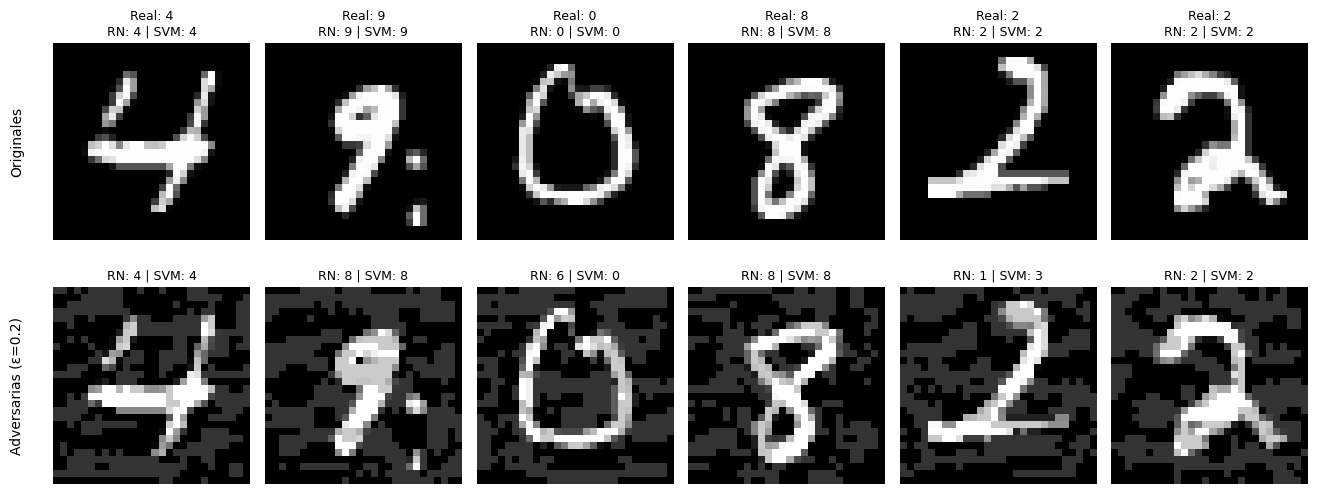

In [8]:
# Dibujamos las originales (fila de arriba) y las adversarias (fila de abajo)
fig, ejes = plt.subplots(2, len(indices), figsize=(2.2 * len(indices), 5.4))

for i in range(len(indices)):
    # Imagen original con las predicciones de ambos modelos
    ejes[0, i].imshow(x_orig[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ejes[0, i].set_title(f"Real: {y_orig[i]}\nRN: {pred_rn_orig[i]} | SVM: {pred_svm_orig[i]}", fontsize=9)
    ejes[0, i].axis("off")

    # Imagen adversaria con las predicciones de ambos modelos
    ejes[1, i].imshow(x_adv[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ejes[1, i].set_title(f"RN: {pred_rn_adv[i]} | SVM: {pred_svm_adv[i]}", fontsize=9)
    ejes[1, i].axis("off")

ejes[0, 0].text(-0.15, 0.5, "Originales", transform=ejes[0, 0].transAxes, rotation=90, va="center", ha="right")
ejes[1, 0].text(-0.15, 0.5, f"Adversarias (ε={EPSILON})", transform=ejes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

#### 4.1 Interpretación

La tabla y las figuras permiten observar qué etiquetas cambian en estas seis muestras. El ataque usa el gradiente de la red; para la SVM se evalúa transferencia. Una mayor precisión de la SVM en estos ejemplos no demuestra robustez frente a ataques diseñados contra ella.

Las cifras de otros modelos o de los apuntes no son resultados de esta arquitectura. El apartado 5 mide el error sobre las 10.000 imágenes del test; no se infiere ese error a partir de seis ejemplos.

#### Comprobación del ataque

Se verifican forma, finitud, rango y cota de perturbación. Con `epsilon=0` la entrada se conserva; el procesado por lotes debe coincidir con el ataque directo para este modelo sin operaciones que mezclen muestras en inferencia. Las comprobaciones se ejecutan tras entrenar la red y no acreditan por sí solas eficacia del ataque.

In [9]:
def fgsm_batch(modelo, x, y, epsilon, batch_size=256):
    """Aplica FGSM por lotes sin cambiar el orden de las imágenes."""
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError('batch_size debe ser un entero positivo.')
    x_adv = np.empty_like(x)
    for i in range(0, len(x), batch_size):
        x_adv[i:i + batch_size] = fgsm(modelo, x[i:i + batch_size], y[i:i + batch_size], epsilon)
    return x_adv


# Comprobaciones numéricas sobre imágenes reales y la red ya entrenada.
x_prueba, y_prueba = x_test[:7], y_test[:7]
adv_directo = fgsm(red_neuronas, x_prueba, y_prueba, EPSILON)
adv_lotes = fgsm_batch(red_neuronas, x_prueba, y_prueba, EPSILON, batch_size=3)
assert adv_directo.shape == x_prueba.shape
assert np.all(np.isfinite(adv_directo))
assert np.all((adv_directo >= 0) & (adv_directo <= 1))
assert np.max(np.abs(adv_directo - x_prueba)) <= EPSILON + 1e-6
np.testing.assert_array_equal(fgsm(red_neuronas, x_prueba, y_prueba, 0), x_prueba)
np.testing.assert_allclose(adv_directo, adv_lotes, atol=1e-6, rtol=0)
for epsilon_invalido in (-1, np.inf, np.nan):
    try:
        fgsm(red_neuronas, x_prueba, y_prueba, epsilon_invalido)
    except ValueError:
        pass
    else:
        raise AssertionError('FGSM debe rechazar epsilon inválido.')
print('FGSM: forma, finitud, rango, cota, epsilon cero y lotes: OK')

FGSM: forma, finitud, rango, cota, epsilon cero y lotes: OK


### 5. Evaluación en todo el conjunto de test (opcional)

Se generan adversarias para las 10.000 imágenes de test con la red original y se calcula el error de ambos modelos. Se procesa por lotes de 256 para limitar la memoria del cálculo del gradiente. Esto conserva el ataque por muestra de la arquitectura usada. Las etiquetas verdaderas definen un ataque no dirigido y el test no se utiliza para entrenar.

In [10]:
if EJECUTAR_OPCIONALES:
    # -----------------------------------------------------------------------------
    # APARTADO 5: Generar adversarias para test completo y evaluar error
    # -----------------------------------------------------------------------------
    
    print("Generando 10.000 imágenes adversarias para el conjunto de test...")
    # Atacamos el conjunto de test completo con la red neuronal original
    x_test_adv_full = fgsm_batch(red_neuronas, x_test, y_test, EPSILON)
    
    # 1. Error de la Red Neuronal sobre el conjunto adversario
    perdida_rn_adv, acierto_rn_adv = red_neuronas.evaluate(x_test_adv_full, y_test, verbose=0)
    error_rn_adv = 1.0 - acierto_rn_adv
    print(f"Acierto Red Neuronal (test adversario): {acierto_rn_adv:.4f} -> Error: {error_rn_adv:.4f}")
    
    # 2. Error de la SVM sobre el conjunto adversario
    # Aplanamos las imágenes para pasarlas por la SVM
    x_test_adv_full_svm = x_test_adv_full.reshape(len(x_test_adv_full), -1)
    acierto_svm_adv = svm.score(x_test_adv_full_svm, y_test)
    error_svm_adv = 1.0 - acierto_svm_adv
    print(f"Acierto SVM (test adversario): {acierto_svm_adv:.4f} -> Error: {error_svm_adv:.4f}")
else:
    print('Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.')

Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.


### 6. Entrenamiento adversario (opcional)

Para entrenar con 120.000 imágenes, primero necesitamos generar las 60.000 imágenes adversarias del conjunto de entrenamiento. Al hacer pasar 60.000 imágenes de golpe por `tf.GradientTape`, es muy probable que ocurra un error de memoria. Por ello, se utiliza la función auxiliar `fgsm_batch`, que aplica el ataque procesando las imágenes en lotes.

Una vez generadas:
1. Concatenamos los datos originales con los adversarios para obtener un conjunto de entrenamiento de 120.000 imágenes y un test de 20.000.
2. Barajamos el conjunto de entrenamiento para que la red no lea primero todas las originales y luego todas las adversarias.
3. Entrenamos desde cero una **nueva red neuronal** y una **nueva SVM** con este conjunto combinado para evaluar si mejora su respuesta ante el ataque.


#### Limitaciones del protocolo

Se mantienen la arquitectura, el optimizador y las 15 épocas. Las adversarias de entrenamiento se generan **una sola vez contra la red original**: es ampliación estática de datos, no un ataque recalculado durante cada actualización de la red robusta. El test mixto usa también el ataque contra la red original; mide resistencia a ese conjunto fijo.

`validation_split=0.1` reserva 12.000 imágenes de las 120.000: la red ajusta sus pesos con 108.000 y la SVM usa las 120.000. El barajado individual puede repartir una imagen original y su adversaria entre entrenamiento y validación. Esta dependencia puede favorecer la métrica de validación; no se usa para elegir épocas ni se mezcla el test externo con entrenamiento. **Pendiente de decisión para la entrega definitiva:** separar por imagen de origen o entrenar con las 120.000 sin validación interna. No se modifica este protocolo silenciosamente ni se presenta su validación como independiente.

La SVM sobre 120.000 imágenes puede requerir mucho tiempo y memoria. Si no se ejecuta, el apartado permanece implementado pero sin resultado acreditado.


In [11]:
if EJECUTAR_OPCIONALES:
    print("Generando 60.000 imágenes adversarias de entrenamiento...")
    x_train_adv_full = fgsm_batch(red_neuronas, x_train, y_train, EPSILON)
    
    # Concatenamos los datos para obtener los conjuntos combinados (120k train, 20k test)
    x_train_120k = np.concatenate([x_train, x_train_adv_full])
    y_train_120k = np.concatenate([y_train, y_train])
    
    x_test_20k = np.concatenate([x_test, x_test_adv_full])
    y_test_20k = np.concatenate([y_test, y_test])
    
    # Barajamos aleatoriamente el nuevo conjunto de train para que la red no lea 
    # Primero todas las originales y luego todas las adversarias (fijando semilla)
    rng = np.random.default_rng(42)
    indices_120k = rng.permutation(len(x_train_120k))
    x_train_120k = x_train_120k[indices_120k]
    y_train_120k = y_train_120k[indices_120k]
    
    # Creamos las vistas aplanadas para entrenar la SVM robusta
    x_train_120k_svm = x_train_120k.reshape(len(x_train_120k), -1)
    x_test_20k_svm = x_test_20k.reshape(len(x_test_20k), -1)
    
    # Entrenamos una NUEVA Red Neuronal idéntica a la del apartado 1
    red_neuronas_adv = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(8, (5, 5), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(24, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    
    red_neuronas_adv.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    
    print("Entrenando Red Neuronal robusta (120.000 imágenes)...")
    red_neuronas_adv.fit(x_train_120k, y_train_120k, epochs=15, batch_size=64, validation_split=0.1)
    
    # Evaluamos la Red Neuronal robusta en el test conjunto de 20.000
    perdida_rn_20k, acierto_rn_20k = red_neuronas_adv.evaluate(x_test_20k, y_test_20k, verbose=0)
    print(f"Error de la Red Neuronal robusta en test conjunto (20k): {1.0 - acierto_rn_20k:.4f}")
    
    # Entrenamos la NUEVA SVM robusta
    # AVISO: Entrenar una SVM es de complejidad casi O(N^2) o O(N^3). Con 120.000 datos
    # Tardará significativamente más que en el apartado 2 (puede llevar desde varios minutos a un par de horas).
    print("Entrenando SVM robusta (120.000 imágenes)...")
    svm_adv = SVC(kernel="rbf", C=10, gamma=0.01)
    svm_adv.fit(x_train_120k_svm, y_train_120k)
    
    # Evaluamos la SVM robusta en el test conjunto de 20.000
    acierto_svm_20k = svm_adv.score(x_test_20k_svm, y_test_20k)
    print(f"Error de la SVM robusta en test conjunto (20k): {1.0 - acierto_svm_20k:.4f}")
else:
    print('Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.')

Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.


### 7. Imágenes “doblemente adversarias” (opcional)

En este apartado tomamos las 60.000 imágenes de entrenamiento que ya tenían el ruido $\epsilon$ inyectado respecto a la red original, y las **volvemos a atacar**. 

Para examinar la respuesta del nuevo modelo entrenado adversariamente, calculamos los gradientes respecto a esta *nueva* red neuronal (`red_neuronas_adv`) y sumamos el nuevo error a la imagen que ya estaba previamente modificada. Finalmente, comprobamos qué rendimiento obtiene el modelo robusto sobre estas imágenes.

La segunda perturbación tiene cota $\epsilon$ respecto a la imagen ya atacada; respecto a la imagen original la cota acumulada es $2\epsilon$ (y puede reducirse por el recorte). No equivale a un ataque de dos pasos proyectado en la bola original de radio $\epsilon$. El rendimiento en train es descriptivo; la evaluación en test permite examinar generalización. Se evalúan tanto la red robusta como la SVM robusta sobre el ataque generado contra la nueva red.


In [12]:
if EJECUTAR_OPCIONALES:
    # -----------------------------------------------------------------------------
    # APARTADO 7: Ataque doblemente adversario
    # -----------------------------------------------------------------------------
    
    print("Generando imágenes doblemente adversarias (atacando 60.000 de train)...")
    # Atacamos las imágenes que ya eran adversarias (x_train_adv_full).
    # Utilizamos la nueva red_neuronas_adv para generar el gradiente de este segundo ataque.
    x_train_adv_doble = fgsm_batch(red_neuronas_adv, x_train_adv_full, y_train, EPSILON)
    
    # Calculamos el rendimiento del modelo robusto sobre estas 60.000 doblemente adversarias
    perdida_doble, acierto_doble = red_neuronas_adv.evaluate(x_train_adv_doble, y_train, verbose=0)
    print(f"Rendimiento de la Red Neuronal robusta en Train doblemente adversario (60k): {acierto_doble:.4f}")
    
    # Como añadido adicional, hacemos lo mismo para el conjunto de test para ver la generalización (10k)
    x_test_adv_doble = fgsm_batch(red_neuronas_adv, x_test_adv_full, y_test, EPSILON)
    perdida_doble_test, acierto_doble_test = red_neuronas_adv.evaluate(x_test_adv_doble, y_test, verbose=0)
    print(f"Rendimiento de la Red Neuronal robusta en Test doblemente adversario (10k): {acierto_doble_test:.4f}")
    
    # Evaluamos también la transferencia a la SVM entrenada adversariamente.
    print('Acierto SVM robusta en train doblemente adversario:',
          svm_adv.score(x_train_adv_doble.reshape(len(x_train_adv_doble), -1), y_train))
    print('Acierto SVM robusta en test doblemente adversario:',
          svm_adv.score(x_test_adv_doble.reshape(len(x_test_adv_doble), -1), y_test))
    assert np.max(np.abs(x_test_adv_doble - x_test)) <= 2 * EPSILON + 1e-6
else:
    print('Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.')

Apartado opcional no ejecutado: EJECUTAR_OPCIONALES = False.


### Fuentes y criterios de interpretación

- [Enunciado de la práctica](enunciado_practica_1.md).
- [TensorFlow: implementación de FGSM](https://www.tensorflow.org/tutorials/generative/adversarial_fgsm).
- [Keras: selección de la validación y barajado en fit](https://keras.io/api/models/model_training_apis/).

La revisión asistida por IA ha integrado los cuadernos y añadido comprobaciones. Las versiones anteriores y sus resultados se conservan en el historial del repositorio. La confirmación de originalidad de la arquitectura y las limitaciones del protocolo opcional quedan visibles para el feedback del profesor.

- [scikit-learn: SVC y clasificación multiclase](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

### Estado de revisión y cuestiones para feedback

La ejecución del 15 de noviembre de 2026 completa los apartados obligatorios sin errores. La red obtiene **98,82 %** en test y cuenta con **41.074 parámetros**; la SVM obtiene **98,33 %** y utiliza **10.867 vectores de soporte**. Se superan las comprobaciones numéricas de FGSM. En las seis muestras mostradas, la red acierta 3/6 adversarias y la SVM 4/6; estas cifras no estiman el acierto sobre todo el test adversario.

**Pendientes:** confirmar la diferencia de arquitectura respecto a la clase y a otros grupos; ejecutar los opcionales si se desean presentar sus resultados; y decidir el protocolo de validación del entrenamiento adversario. El barajado individual puede separar una imagen original y su adversaria entre entrenamiento y validación. Con `validation_split=0.1`, la red ajusta sus pesos con 108.000 imágenes y valida con 12.000, mientras la SVM utiliza las 120.000. Esta limitación permanece explícita en el apartado 6.

Se preservan la arquitectura, los hiperparámetros y el procedimiento de ataque. La revisión ha añadido validación de parámetros y comprobaciones de FGSM, procesado por lotes para el test completo y evaluación de la SVM robusta en el segundo ataque. Los opcionales permanecen sin resultados acreditados.